First five rows:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       

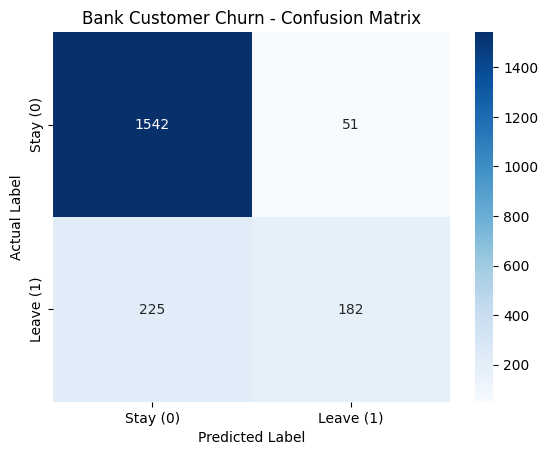

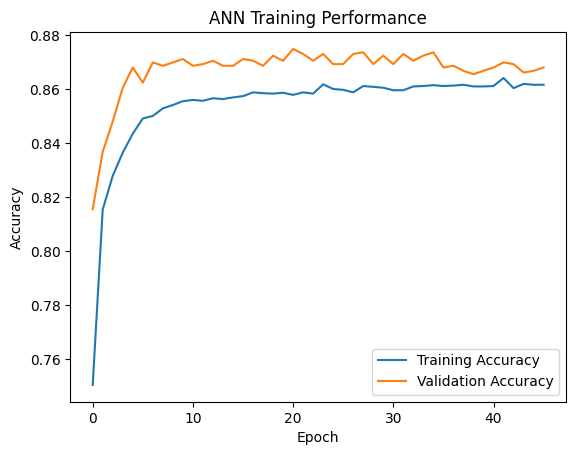

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

#pip install pandas numpy scikit-learn tensorflow matplotlib seaborn

# Step 1: Load the dataset
data = pd.read_csv("/content/Churn_Modelling.csv")

print("First five rows:")
print(data.head())

print("\nDataset Information:")
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nTarget Distribution:")
print(data["Exited"].value_counts())

# Step 2: Separate features and target
# Remove customer identifiers and the target column
X = data.drop(
    columns=["RowNumber", "CustomerId", "Surname", "Exited"]
)
y = data["Exited"]

# Identify categorical and numerical features
categorical_features = ["Geography", "Gender"]
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

# Step 3: Encode categorical features and scale numerical features
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore",
                          drop="first"), categorical_features)
])

# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit preprocessing only on training data
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Convert to dense arrays for ANN
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

# Step 5: Build the ANN model
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"), # ReLU: Used in hidden layers (max(0,x))
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")  # Sigmoid: Used in the output layer to predict the probability of a customer leaving the bank.
])

# Step 6: Compile and train the model
model.compile(
    optimizer="adam", #ANN makes predictions, checks its errors,adjusts the weights to improve future predictions.
    loss="binary_crossentropy", #measures how wrong the model's predictions are
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# Step 7: Predict churn labels
probabilities = model.predict(X_test, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print("\nTest Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay (0)", "Leave (1)"],
    yticklabels=["Stay (0)", "Leave (1)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Bank Customer Churn - Confusion Matrix")
plt.show()

# Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Training Performance")
plt.legend()
plt.show()
